In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pollut=pd.read_csv('../data/raw/Pollut_20261020110951_20200101_20261020_11_00.csv', sep=';')

In [35]:
import requests
import json
import os

METRO_DEPTS = (
    {f"{i:02d}" for i in range(1, 20)}
    | {'2A', '2B'}
    | {f"{i:02d}" for i in range(21, 96)}
)

def get_departement(lat, lon):
    url = f"https://geo.api.gouv.fr/communes?lat={lat}&lon={lon}&fields=departement"
    r = requests.get(url)
    if r.ok and r.json():
        code = r.json()[0]['departement']['code']
        return code if code in METRO_DEPTS else None
    return None

# Chargement du cache existant
if os.path.exists('sites_dept.json'):
    with open('sites_dept.json') as f:
        resultats = json.load(f)
else:
    resultats = {}

sites = pollut[['code site', 'Latitude', 'Longitude']].drop_duplicates('code site').reset_index(drop=True)
nouveaux = sites[~sites['code site'].isin(resultats)]

for i, row in nouveaux.iterrows():
    if i % 10 == 0:
        print(f"{i}/{len(nouveaux)}")
    resultats[row['code site']] = get_departement(row['Latitude'], row['Longitude'])

# Sauvegarde du cache
with open('sites_dept.json', 'w') as f:
    json.dump(resultats, f)

sites['code_dept'] = sites['code site'].map(resultats)
pollut = pollut.merge(sites[['code site', 'code_dept']], on='code site', how='left')

In [36]:
display(pollut.head(5))

,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude,code_dept
0,2019/12/02 00:00:00,2020/01/01 00:00:00,ATMO OCCITANIE,FR76ZRE01,ZR OCCITANIE,FR12047,Bessiere Econotre,Rurale près des villes,Pb in PM10,Industrielle,...,0.0020,µg-m3,NaN,NaN,NaN,A,1,43.803139,1.595475,31
1,2019/12/02 00:00:00,2020/01/01 00:00:00,ATMO OCCITANIE,FR76ZRE01,ZR OCCITANIE,FR12047,Bessiere Econotre,Rurale près des villes,As in PM10,Industrielle,...,0.3000,ng-m3,NaN,NaN,NaN,A,1,43.803139,1.595475,31
2,2019/12/02 00:00:00,2020/01/01 00:00:00,ATMO OCCITANIE,FR76ZRE01,ZR OCCITANIE,FR12047,Bessiere Econotre,Rurale près des villes,Cd in PM10,Industrielle,...,0.1100,ng-m3,NaN,NaN,NaN,A,1,43.803139,1.595475,31
3,2019/12/02 00:00:00,2020/01/01 00:00:00,ATMO OCCITANIE,FR76ZRE01,ZR OCCITANIE,FR12047,Bessiere Econotre,Rurale près des villes,Ni in PM10,Industrielle,...,0.3000,ng-m3,NaN,NaN,NaN,A,1,43.803139,1.595475,31
4,2019/12/04 14:01:00,2020/01/01 00:00:00,ATMO OCCITANIE,FR76ZRE01,ZR OCCITANIE,FR12050,Place du 8 Mai,Urbaine,Pb in PM10,Industrielle,...,0.0025,µg-m3,NaN,NaN,NaN,A,1,44.560544,2.226169,12


In [37]:
pollut_tri=pollut.copy()
pollut_tri= pollut_tri.reset_index(drop=True)
pollut_tri['valeur'] = pollut_tri['valeur'].where(pollut_tri['valeur'] >= 0)

print(pollut_tri.columns.tolist())
print(pollut_tri["Polluant"].value_counts())

# Le polluant C6H6 n'est pas approprié pour notre étude (cf. texte)
# Les polluants SO2 et NO2 ne sont pas assez représentés => à éliminer du dataset
pollut_tri=pollut_tri[pollut_tri["Polluant"]!='C6H6']
pollut_tri=pollut_tri[pollut_tri["Polluant"]!='NO2']
pollut_tri=pollut_tri[pollut_tri["Polluant"]!='SO2']

polluants=pollut_tri["Polluant"].unique().tolist()
#On ne garde que les stations qui mesurent de fond de pollution, pas les pics aigus
pollut_tri = pollut_tri[pollut_tri["type d'influence"] == 'Fond']
#On ne garde que les mesures validées (presque toutes)
pollut_tri = pollut_tri[pollut_tri["validité"] != -1]
display(pollut_tri.head(5))

['Date de début', 'Date de fin', 'Organisme', 'code zas', 'Zas', 'code site', 'nom site', "type d'implantation", 'Polluant', "type d'influence", 'Réglementaire', "type d'évaluation", 'type de valeur', 'valeur', 'valeur brute', 'unité de mesure', 'taux de saisie', 'couverture temporelle', 'couverture de données', 'code qualité', 'validité', 'Latitude', 'Longitude', 'code_dept']
Polluant
BaP in PM10    19340
Ni in PM10      6481
C6H6            6471
Pb in PM10      6413
Cd in PM10      6259
As in PM10      6258
SO2              130
NO2               38
Name: count, dtype: int64


,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude,code_dept
16,2019/12/12 23:59:00,2020/01/01 00:00:00,ATMO SUD,FR93ZAG01,ZAG MARSEILLE-AIX,FR02013,Fos-Sur-Mer - Station Fos Les Carabins,Périurbaine,Pb in PM10,Fond,...,0.0031,µg-m3,NaN,NaN,NaN,A,1,43.458927,4.934572,13
17,2019/12/12 23:59:00,2020/01/01 00:00:00,ATMO SUD,FR93ZAG01,ZAG MARSEILLE-AIX,FR03043,Marseille - Station Marseille Cinq Avenues,Urbaine,Pb in PM10,Fond,...,0.0043,µg-m3,NaN,NaN,NaN,A,1,43.305287,5.394716,13
19,2019/12/12 23:59:00,2020/01/01 00:00:00,ATMO SUD,FR93ZAG01,ZAG MARSEILLE-AIX,FR02013,Fos-Sur-Mer - Station Fos Les Carabins,Périurbaine,As in PM10,Fond,...,0.4300,ng-m3,NaN,NaN,NaN,A,1,43.458927,4.934572,13
20,2019/12/12 23:59:00,2020/01/01 00:00:00,ATMO SUD,FR93ZAG01,ZAG MARSEILLE-AIX,FR03043,Marseille - Station Marseille Cinq Avenues,Urbaine,As in PM10,Fond,...,0.3200,ng-m3,NaN,NaN,NaN,A,1,43.305287,5.394716,13
22,2019/12/12 23:59:00,2020/01/01 00:00:00,ATMO SUD,FR93ZAG01,ZAG MARSEILLE-AIX,FR02013,Fos-Sur-Mer - Station Fos Les Carabins,Périurbaine,Cd in PM10,Fond,...,0.1000,ng-m3,NaN,NaN,NaN,A,1,43.458927,4.934572,13


In [38]:
pollut_tri['Date de fin'] = pd.to_datetime(pollut_tri['Date de fin'])
iso = pollut_tri['Date de fin'].dt.isocalendar()
pollut_tri['week'] = iso.week
pollut_tri['year'] = iso.year  # ← année ISO, pas calendaire

mask_temporel = pollut_tri['year'].isin([2020, 2021, 2022, 2023, 2024, 2025])
pollut_tri = pollut_tri[mask_temporel].copy()

pollut_week = pollut_tri.pivot_table(
    index=['code_dept', 'year', 'week'],
    columns='Polluant',
    values='valeur'
).reset_index()

pollut_week['date_semaine'] = pollut_week.apply(
    lambda r: f"{int(r['year'])}-S{int(r['week']):02d}", axis=1
)

display(pollut_week.head(5))

Polluant,code_dept,year,week,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,date_semaine
0,02,2020,12,0.18,NaN,0.05,0.39,0.0021,2020-S12
1,02,2020,13,0.36,NaN,0.13,0.47,0.0045,2020-S13
2,02,2020,14,0.58,NaN,0.28,0.78,0.0078,2020-S14
3,02,2020,15,0.32,NaN,0.15,0.71,0.0039,2020-S15
4,02,2020,29,0.21,NaN,0.05,0.77,0.0020,2020-S29


In [39]:
polluants = ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10']
toutes_dates = sorted(pollut_week['date_semaine'].unique())
records_interp = []

for dept in pollut_week['code_dept'].dropna().unique():
    df_dept = pollut_week[pollut_week['code_dept'] == dept][['date_semaine'] + polluants].set_index('date_semaine')
    df_dept = df_dept.reindex(toutes_dates)

    for pol in polluants:
        n_mesures = df_dept[pol].notna().sum()
        if n_mesures >= 3:
            df_dept[pol] = df_dept[pol].interpolate(method='linear', limit_area='inside')
        else:
            df_dept[pol] = np.nan

    df_dept['code_dept'] = dept
    records_interp.append(df_dept.reset_index().rename(columns={'index': 'date_semaine'}))

df_temporal = pd.concat(records_interp, ignore_index=True)
display(df_temporal.head(5))

#print(pollut_week.groupby('date_semaine').size().describe())

Polluant,date_semaine,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,code_dept
0,2020-S01,NaN,NaN,NaN,NaN,NaN,02
1,2020-S02,NaN,NaN,NaN,NaN,NaN,02
2,2020-S03,NaN,NaN,NaN,NaN,NaN,02
3,2020-S04,NaN,NaN,NaN,NaN,NaN,02
4,2020-S05,NaN,NaN,NaN,NaN,NaN,02


In [40]:
#!pip install geopandas
import geopandas as gpd

geo = gpd.read_file("https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson").set_index('code')

voisins = {}
for dept in geo.index:
    touches = geo[geo.geometry.touches(geo.loc[dept, 'geometry'])].index.tolist()
    voisins[dept] = touches

# Ajout manuel des liens Corse <-> continent
for dept_corse in ['2A', '2B']:
    for dept_continent in ['06', '83']:
        if dept_continent not in voisins[dept_corse]:
            voisins[dept_corse].append(dept_continent)
        if dept_corse not in voisins[dept_continent]:
            voisins[dept_continent].append(dept_corse)

df_voisins = pd.DataFrame([
    {'code_dept': dept, 'voisins': voisins[dept]}
    for dept in voisins
]).sort_values('code_dept').reset_index(drop=True)

#df_voisins.to_csv('Voisins.csv')

In [41]:
week = toutes_dates[0]
pol = polluants[0]

tous_depts = [f"{i:02d}" for i in range(1, 96) if i != 20] + ['2A', '2B']
s_full = pd.Series(np.nan, index=tous_depts, name=pol)

s_source = df_temporal[df_temporal['date_semaine'] == week].set_index('code_dept')[pol]
s_full.update(s_source)
s = s_full.copy()
n = 0

print(f"Avant toute passe — Départements manquants : {s.isna().sum()}")
print(f"Départements remplis : {s.notna().sum()}")
print(s[s.notna()].index.tolist())

Avant toute passe — Départements manquants : 79
Départements remplis : 17
['06', '08', '13', '18', '22', '26', '31', '32', '38', '42', '44', '63', '67', '69', '75', '76', '80']


Passe 1 — manquants : 63 — remplis : 33


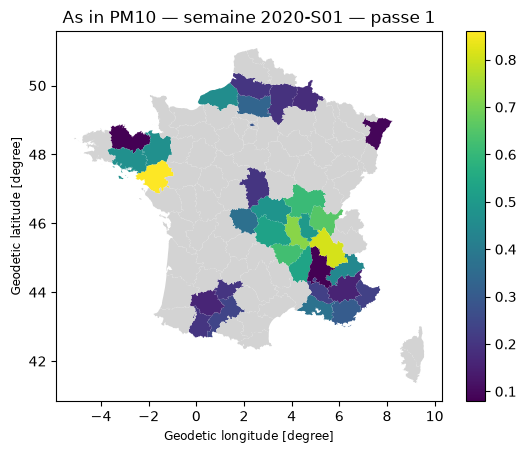

Passe 2 — manquants : 44 — remplis : 52


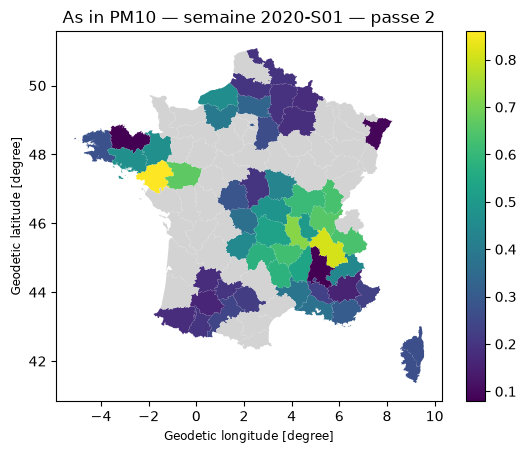

Passe 3 — manquants : 22 — remplis : 74


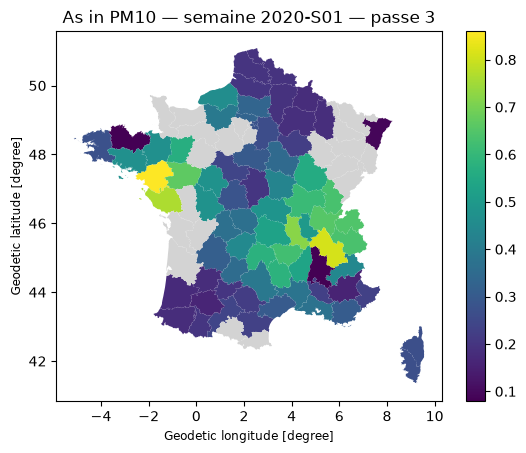

Passe 4 — manquants : 6 — remplis : 90


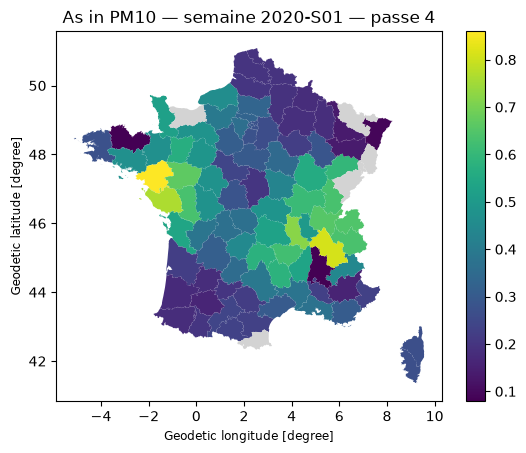

Passe 5 — manquants : 0 — remplis : 96


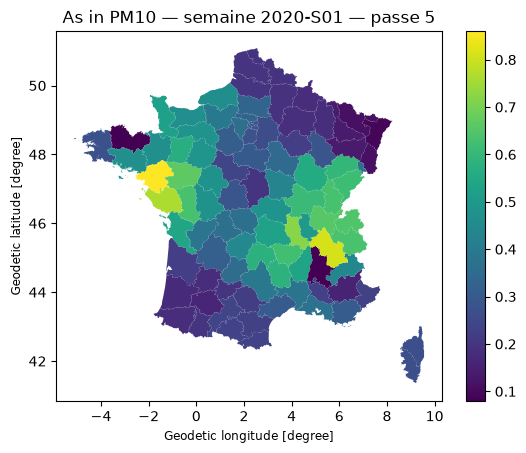

In [42]:
show = True  # passer à False pour désactiver les cartes

# Vérification initiale
if s.notna().sum() == 0:
    print("Aucune mesure disponible — arrêt du processus.")
else:
    # Phase 1 : passes avec >= 2 voisins
    while True:
        n += 1
        s_avant = s.copy()
        for dept in s_avant[s_avant.isna()].index:
            vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
            if len(vois_values) >= 2:
                s[dept] = np.mean(vois_values)

        print(f"Passe {n} — manquants : {s.isna().sum()} — remplis : {s.notna().sum()}")

        if show:
            geo_plot = geo.copy()
            geo_plot['valeur'] = s.rename_axis('code')
            geo_plot.plot(column='valeur', legend=True, missing_kwds={'color': 'lightgrey'})
            plt.title(f"{pol} — semaine {week} — passe {n}")
            plt.show()

        if s.isna().sum() == 0:
            break
        if s.notna().sum() <= s_avant.notna().sum():  # plus de progression
            break

    # Phase 2 : passes exceptionnelles avec >= 1 voisin
    while s.isna().sum() > 0:
        n += 1
        s_avant = s.copy()
        for dept in s_avant[s_avant.isna()].index:
            vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
            if len(vois_values) >= 1:
                s[dept] = np.mean(vois_values)

        print(f"Passe exceptionnelle {n} — manquants : {s.isna().sum()} — remplis : {s.notna().sum()}")

        if show:
            geo_plot = geo.copy()
            geo_plot['valeur'] = s.rename_axis('code')
            geo_plot.plot(column='valeur', legend=True, missing_kwds={'color': 'lightgrey'})
            plt.title(f"{pol} — semaine {week} — passe exceptionnelle {n}")
            plt.show()

        if s.notna().sum() <= s_avant.notna().sum():  # blocage définitif
            print("Impossible de remplir tous les départements — arrêt.")
            break

In [43]:
#!pip install tqdm
from tqdm import tqdm

def coloniser(df_temporal, polluants, toutes_semaines, voisins):
    
    tous_depts = [f"{i:02d}" for i in range(1, 96) if i != 20] + ['2A', '2B']
    
    # Squelette complet dept × date_semaine
    index = pd.MultiIndex.from_product([toutes_semaines, tous_depts], names=['date_semaine', 'code_dept'])
    df_out = pd.DataFrame(index=index).reset_index()

    for pol in polluants:
        print(f"\nPolluant : {pol}")
        df_out[pol] = np.nan
        
        for date_semaine in tqdm(toutes_semaines, desc=pol):
            s_full = pd.Series(np.nan, index=tous_depts, name=pol)
            s_source = df_temporal[df_temporal['date_semaine'] == date_semaine].set_index('code_dept')[pol]
            s_full.update(s_source)
            s = s_full.copy()
            
            if s.notna().sum() == 0:
                continue

            while True:
                s_avant = s.copy()
                for dept in s_avant[s_avant.isna()].index:
                    vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
                    if len(vois_values) >= 2:
                        s[dept] = np.mean(vois_values)
                if s.isna().sum() == 0:
                    break
                if s.notna().sum() <= s_avant.notna().sum():
                    break

            while s.isna().sum() > 0:
                s_avant = s.copy()
                for dept in s_avant[s_avant.isna()].index:
                    vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
                    if len(vois_values) >= 1:
                        s[dept] = np.mean(vois_values)
                if s.notna().sum() <= s_avant.notna().sum():
                    break

            df_out.loc[df_out['date_semaine'] == date_semaine, pol] = \
                df_out.loc[df_out['date_semaine'] == date_semaine, 'code_dept'].map(s).values

    return df_out

In [44]:
df_colonise = coloniser(df_temporal, polluants, toutes_dates, voisins)
df_colonise = df_colonise[df_colonise['date_semaine'].str[:4].isin(['2021', '2022', '2023', '2024'])]
#df_colonise = df_colonise[df_colonise['date_semaine'].str[:4].isin(['2025'])]
df_colonise.to_csv('../data/final_metropole/pollution_2021_2024.csv')


Polluant : As in PM10


As in PM10: 100%|███████████████████████████████████████████████████████| 313/313 [00:08<00:00, 36.63it/s]



Polluant : BaP in PM10


BaP in PM10: 100%|██████████████████████████████████████████████████████| 313/313 [00:08<00:00, 36.77it/s]



Polluant : Cd in PM10


Cd in PM10: 100%|███████████████████████████████████████████████████████| 313/313 [00:09<00:00, 34.52it/s]



Polluant : Ni in PM10


Ni in PM10: 100%|███████████████████████████████████████████████████████| 313/313 [00:09<00:00, 34.08it/s]



Polluant : Pb in PM10


Pb in PM10: 100%|███████████████████████████████████████████████████████| 313/313 [00:09<00:00, 33.48it/s]


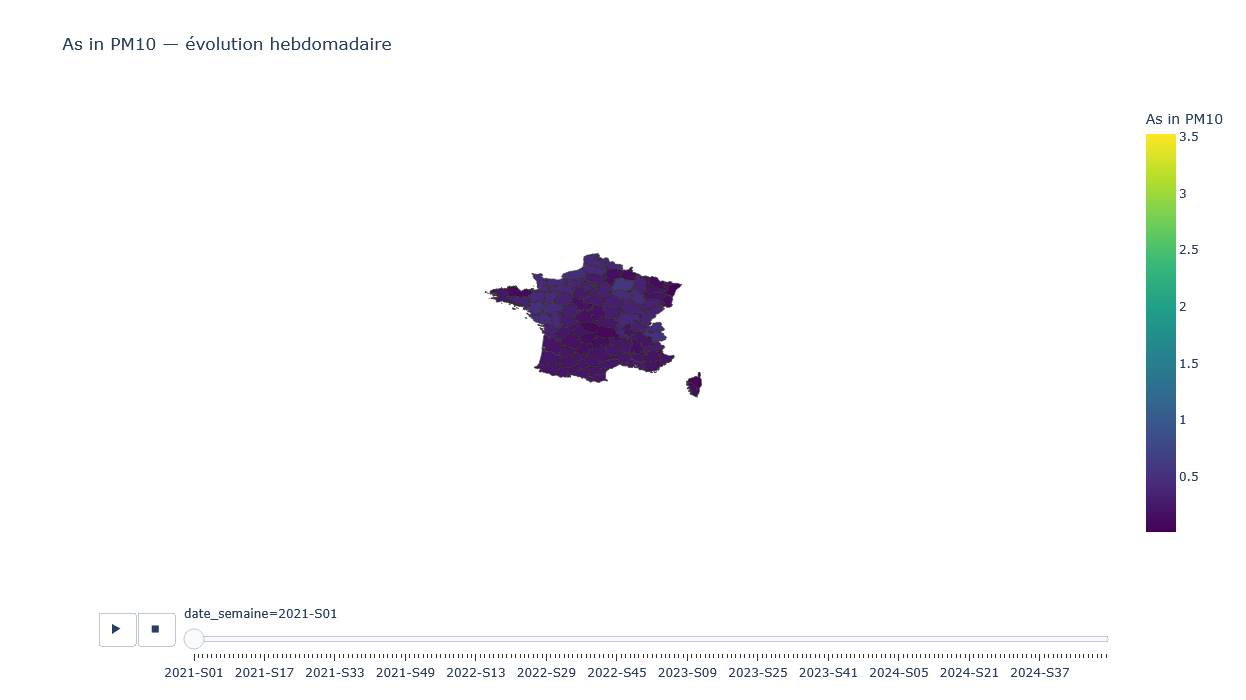

In [45]:
import plotly.express as px

pol_choisi = 'As in PM10'  # modifier ici

df_anim = df_colonise[['date_semaine', 'code_dept', pol_choisi]].copy()

fig = px.choropleth(
    df_anim,
    geojson="https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson",
    locations='code_dept',
    featureidkey='properties.code',
    color=pol_choisi,
    animation_frame='date_semaine',
    color_continuous_scale='Viridis',
    range_color=[df_anim[pol_choisi].min(), df_anim[pol_choisi].max()],
    title=f'{pol_choisi} — évolution hebdomadaire'
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    width=900,
    height=700,
    geo=dict(projection_scale=6, center=dict(lat=46.5, lon=2.5))
)
fig.show()

In [46]:
print(df_colonise.shape)
df= df_colonise.sort_values('date_semaine').reset_index(drop=True)
display(df.head(5))

(19968, 7)


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10
0,2021-S01,01,0.326250,0.610000,0.050000,0.422500,0.002025
1,2021-S01,71,0.405000,0.245000,0.070000,0.990000,0.004000
2,2021-S01,70,0.341875,1.135598,0.085781,0.641250,0.003412
3,2021-S01,69,0.190000,0.230000,0.030000,0.160000,0.001700
4,2021-S01,68,0.125312,0.180897,0.044062,0.236875,0.001556
